In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
#data download:
#!/bin/bash
!kaggle datasets download -d saadpd/menwomen-classification

Dataset URL: https://www.kaggle.com/datasets/saadpd/menwomen-classification
License(s): copyright-authors
100% 806M/806M [00:09<00:00, 93.1MB/s]



In [ ]:
#unzip:
import zipfile
zip_ref = zipfile.ZipFile('/content/menwomen-classification.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
# loading libraries:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization,Conv2D,Dropout,Flatten,MaxPooling2D,GlobalAveragePooling2D
from matplotlib import pyplot as plt
from tensorflow.keras.regularizers import l1, l2

In [ ]:
#generators train,test, validation:
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/traindata/traindata",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "training",
    seed = 123
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/traindata/traindata",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "validation",
    seed = 123
)

test_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/testdata/testdata",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    seed = 123
)

Found 2912 files belonging to 2 classes.
Using 2330 files for training.
Found 2912 files belonging to 2 classes.
Using 582 files for validation.
Found 1333 files belonging to 2 classes.


In [ ]:
#normalization:
def process(image,label):
  image = tf.cast(image/255., tf.float32)
  return image, label
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)
test_ds = test_ds.map(process)

In [ ]:
#CNN architecture:
model = Sequential()

#input layer:
model.add(Conv2D(32,kernel_size=(3,3),padding = "valid", activation = "relu",kernel_regularizer=l2(0.1), input_shape = (256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size = (2,2),strides = 2, padding = "valid"))


#hidden layers:
model.add(Conv2D(64,kernel_size=(3,3),padding = "valid", activation = "relu",kernel_regularizer=l2(0.1)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size = (2,2),strides = 2, padding = "valid"))

#hidden layers:
model.add(Conv2D(64,kernel_size=(3,3),padding = "valid", activation = "relu",kernel_regularizer=l2(0.1)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size = (2,2),strides = 2, padding = "valid"))

#hidden layers:
model.add(Conv2D(128,kernel_size=(3,3),padding = "valid", activation = "relu",kernel_regularizer=l2(0.1)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size = (2,2),strides = 2, padding = "valid"))

model.add(GlobalAveragePooling2D())

# dense layer
model.add(Dense(128, activation = "relu"))
#model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(128, activation = "relu"))
#model.add(BatchNormalization())
model.add(Dropout(0.2))

#output:
model.add(Dense(1, activation = "sigmoid"))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 60, 60, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,481 (642.50 KB)

 Trainable params: 163,905 (640.25 KB)

 Non-trainable params: 576 (2.25 KB)

In [ ]:
#compile:
model.compile(optimizer="adam", loss = "binary_crossentropy", metrics = ["accuracy"])

In [ ]:
history = model.fit(train_ds, epochs =10, batch_size = 32, validation_data = validation_ds, verbose = 1)

Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 318ms/step - accuracy: 0.6279 - loss: 7.0012 - val_accuracy: 0.3471 - val_loss: 1.5587
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 19s 259ms/step - accuracy: 0.6609 - loss: 1.0168 - val_accuracy: 0.6529 - val_loss: 0.8642
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 283ms/step - accuracy: 0.6652 - loss: 0.7827 - val_accuracy: 0.6529 - val_loss: 0.8146
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 21s 283ms/step - accuracy: 0.6695 - loss: 0.7507 - val_accuracy: 0.6598 - val_loss: 0.8241
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 19s 262ms/step - accuracy: 0.6532 - loss: 0.7393 - val_accuracy: 0.6546 - val_loss: 0.7653
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 20s 261ms/step - accuracy: 0.6717 - loss: 0.7179 - val_accuracy: 0.3454 - val_loss: 0.8875
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 19s 257ms/step - accuracy: 0.6635 - loss: 0.7112 - val_accuracy: 0.3471 - val_loss: 0.8708
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 20s 279ms/step - accuracy: 0.6695 - loss: 0.7051 - val_accu

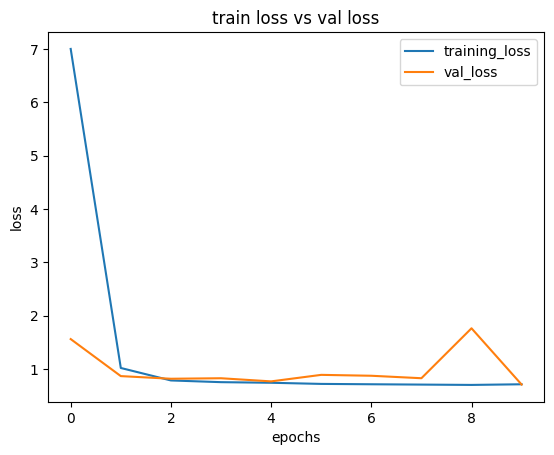

In [ ]:
# graph:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label = "val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

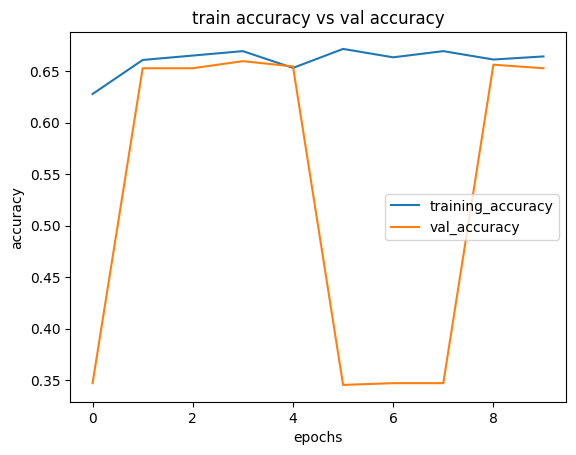

In [ ]:
# graph:
plt.plot(history.history["accuracy"],label="training_accuracy")
plt.plot(history.history["val_accuracy"],label = "val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()

In [ ]:
#model testing on test data:
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 251ms/step - accuracy: 0.6879 - loss: 0.6872
Test Loss: 0.687231719493866
Test Accuracy: 0.6879220008850098


In [ ]:
# model prediction :
import cv2 # vision lib


In [ ]:
#load image:
image = cv2.imread("/content/women image.jpg")


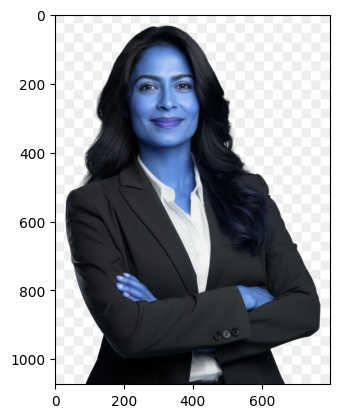

In [ ]:
plt.imshow(image)

In [ ]:
test_image = cv2.resize(image,(256,256))


In [ ]:
test_input =  test_image.reshape((1,256,256,3))

In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[1.]], dtype=float32)

In [ ]:
#load image:
image = cv2.imread("/content/man image.jpg")


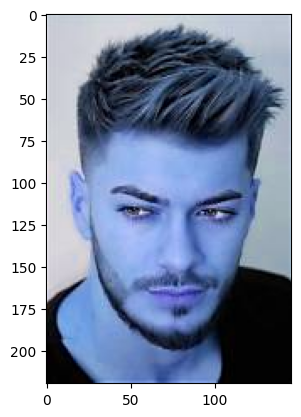

In [ ]:
plt.imshow(image)

In [ ]:
test_image = cv2.resize(image,(256,256))


In [ ]:
test_input =  test_image.reshape((1,256,256,3))

In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


array([[1.]], dtype=float32)